# TASK 3

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving ratings_117.data to ratings_117.data
Saving movies_117.item to movies_117.item


In [ ]:

import os

print("Files uploaded:")
for filename in ["ratings_117.data", "movies_117.item"]:
    if os.path.exists(filename):
        print(f"{filename}: {os.path.getsize(filename):,} bytes")
    else:
        print(f"{filename}: NOT FOUND")


Files uploaded:
ratings_117.data: 1,755,727 bytes
movies_117.item: 236,344 bytes


In [ ]:

import pandas as pd
import numpy as np
from scipy import stats

# Load the ratings dataset
ratings = pd.read_csv(
    "ratings_117.data",
    sep="\t",
    header=None,
    names=["user_id", "movie_id", "rating", "timestamp"]
)

print("Dataset shape:", ratings.shape)
print("\nFirst 5 rows:")
display(ratings.head())

print("\nData types:")
print(ratings.dtypes)

print("\nMissing values:")
print(ratings.isnull().sum())

print("\nRating distribution:")
print(ratings["rating"].value_counts().sort_index())


Dataset shape: (84392, 4)

First 5 rows:


,user_id,movie_id,rating,timestamp
0,670,333,4,883453227
1,87,228,3,884724109
2,331,210,4,878850587
3,585,477,4,884257540
4,268,451,4,889115411



Data types:
user_id      int64
movie_id     int64
rating       int64
timestamp    int64
dtype: object

Missing values:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

Rating distribution:
rating
1     4939
2     9488
3    22892
4    28911
5    18162
Name: count, dtype: int64


In [ ]:

# Central tendency
print("Mean:", ratings["rating"].mean())
print("Median:", ratings["rating"].median())
print("Mode:", ratings["rating"].mode().tolist())

# Dispersion
print("Variance:", ratings["rating"].var())
print("Standard deviation:", ratings["rating"].std())
print("Minimum:", ratings["rating"].min())
print("Maximum:", ratings["rating"].max())

# Position measures
print("Q1:", ratings["rating"].quantile(0.25))
print("Q2 (Median):", ratings["rating"].quantile(0.50))
print("Q3:", ratings["rating"].quantile(0.75))
print("IQR:", ratings["rating"].quantile(0.75)
      - ratings["rating"].quantile(0.25))


Mean: 3.5435230827566593
Median: 4.0
Mode: [4]
Variance: 1.2545430166382268
Standard deviation: 1.1200638448937752
Minimum: 1
Maximum: 5
Q1: 3.0
Q2 (Median): 4.0
Q3: 4.0
IQR: 1.0


In [ ]:

# Number of ratings received by each movie
ratings_per_movie = ratings.groupby("movie_id")["rating"].count()

# Number of ratings given by each user
ratings_per_user = ratings.groupby("user_id")["rating"].count()

print("Unique movies rated:", ratings["movie_id"].nunique())
print("Unique users:", ratings["user_id"].nunique())

print("\nRatings per movie:")
print(ratings_per_movie.describe())

print("\nRatings per user:")
print(ratings_per_user.describe())


Unique movies rated: 1657
Unique users: 919

Ratings per movie:
count    1657.000000
mean       50.930597
std        68.479743
min         1.000000
25%         5.000000
50%        23.000000
75%        67.000000
max       500.000000
Name: rating, dtype: float64

Ratings per user:
count    919.000000
mean      91.830250
std       99.899784
min        1.000000
25%       25.000000
50%       53.000000
75%      131.500000
max      737.000000
Name: rating, dtype: float64


In [ ]:

# Skewness of the rating distribution
print("Rating mean:", ratings["rating"].mean())
print("Rating median:", ratings["rating"].median())
print("Rating skewness:", ratings["rating"].skew())

# IQR method for unusual movies by rating count
q1 = ratings_per_movie.quantile(0.25)
q3 = ratings_per_movie.quantile(0.75)
iqr = q3 - q1

upper_fence = q3 + 1.5 * iqr
unusual_movies_iqr = ratings_per_movie[ratings_per_movie > upper_fence]

print("\nMovie rating-count Q1:", q1)
print("Movie rating-count Q3:", q3)
print("Movie rating-count IQR:", iqr)
print("Upper outlier fence:", upper_fence)
print("Unusual movies by IQR:", len(unusual_movies_iqr))
print(unusual_movies_iqr.sort_values(ascending=False).head(10))

# Z-scores for movie rating counts
movie_count_z = (ratings_per_movie - ratings_per_movie.mean()) / ratings_per_movie.std()
unusual_movies_z = movie_count_z[movie_count_z.abs() > 3]

print("\nUnusual movies by |z-score| > 3:", len(unusual_movies_z))
print(unusual_movies_z.sort_values(ascending=False).head(10))


Rating mean: 3.5435230827566593
Rating median: 4.0
Rating skewness: -0.5142095625397555

Movie rating-count Q1: 5.0
Movie rating-count Q3: 67.0
Movie rating-count IQR: 62.0
Upper outlier fence: 160.0
Unusual movies by IQR: 130
movie_id
50     500
181    436
258    433
100    432
286    413
294    407
288    402
1      386
300    369
121    360
Name: rating, dtype: int64

Unusual movies by |z-score| > 3: 34
movie_id
50     6.557697
181    5.623114
258    5.579305
100    5.564703
286    5.287248
294    5.199631
288    5.126617
1      4.892971
300    4.644722
121    4.513297
Name: rating, dtype: float64


In [ ]:

# Inspect the movies file format
with open("movies_117.item", "r", encoding="latin-1") as f:
    for _ in range(3):
        print(repr(f.readline()))


'1|Toy Story (1995)|01-Jan-1995||http://us.imdb.com/M/title-exact?Toy%20Story%20(1995)|0|0|0|1|1|1|0|0|0|0|0|0|0|0|0|0|0|0|0\n'
'2|GoldenEye (1995)|01-Jan-1995||http://us.imdb.com/M/title-exact?GoldenEye%20(1995)|0|1|1|0|0|0|0|0|0|0|0|0|0|0|0|0|1|0|0\n'
'3|Four Rooms (1995)|01-Jan-1995||http://us.imdb.com/M/title-exact?Four%20Rooms%20(1995)|0|0|0|0|0|0|0|0|0|0|0|0|0|0|0|0|1|0|0\n'


In [ ]:

# MovieLens movie-file columns
movie_columns = [
    "movie_id", "title", "release_date", "video_release_date", "imdb_url",
    "unknown", "Action", "Adventure", "Animation", "Children", "Comedy",
    "Crime", "Documentary", "Drama", "Fantasy", "Film_Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci_Fi", "Thriller", "War", "Western"
]

movies = pd.read_csv(
    "movies_117.item",
    sep="|",
    header=None,
    names=movie_columns,
    encoding="latin-1"
)

# Join ratings with movie information
movie_ratings = ratings.merge(
    movies[["movie_id", "title"] + movie_columns[5:]],
    on="movie_id",
    how="left"
)

print("Movies loaded:", len(movies))
print("Unique movie IDs:", movies["movie_id"].nunique())
print("Joined ratings rows:", len(movie_ratings))
print("Missing movie matches:", movie_ratings["title"].isna().sum())

print("\nGenre counts:")
print(movies[movie_columns[5:]].sum().sort_values(ascending=False))


Movies loaded: 1682
Unique movie IDs: 1682
Joined ratings rows: 84392
Missing movie matches: 0

Genre counts:
Drama          725
Comedy         505
Action         251
Thriller       251
Romance        247
Adventure      135
Children       122
Crime          109
Sci_Fi         101
Horror          92
War             71
Mystery         61
Musical         56
Documentary     50
Animation       42
Western         27
Film_Noir       24
Fantasy         22
unknown          2
dtype: int64


In [ ]:

# 1. Probability that a randomly selected rating is 5
p_rating_5 = (ratings["rating"] == 5).mean()

# Define a liked rating as rating >= 4
movie_ratings["liked"] = movie_ratings["rating"] >= 4

# 2. P(rating >= 4 | Drama)
p_liked_drama = movie_ratings.loc[
    movie_ratings["Drama"] == 1, "liked"
].mean()

# 3. P(rating >= 4 | Horror)
p_liked_horror = movie_ratings.loc[
    movie_ratings["Horror"] == 1, "liked"
].mean()

# 4. P(Drama | rating = 5)
p_drama_given_5 = movie_ratings.loc[
    movie_ratings["rating"] == 5, "Drama"
].mean()

print(f"P(rating = 5): {p_rating_5:.4f}")
print(f"P(rating >= 4 | Drama): {p_liked_drama:.4f}")
print(f"P(rating >= 4 | Horror): {p_liked_horror:.4f}")
print(f"P(Drama | rating = 5): {p_drama_given_5:.4f}")


P(rating = 5): 0.2152
P(rating >= 4 | Drama): 0.6200
P(rating >= 4 | Horror): 0.4834
P(Drama | rating = 5): 0.4698


In [ ]:

# Create a contingency table
contingency = pd.crosstab(
    movie_ratings["liked"],
    movie_ratings["Comedy"] == 1
)

print("Contingency table (rows: liked, columns: Comedy):")
display(contingency)

# Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.8f}")
print("\nExpected frequencies:")
display(pd.DataFrame(expected,
                     index=contingency.index,
                     columns=contingency.columns))

alpha = 0.05
if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("Conclusion: Rating preference and Comedy genre are associated.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Conclusion: No statistically significant association was detected.")


Contingency table (rows: liked, columns: Comedy):


Comedy,False,True
liked,,
False,24835,12484
True,34329,12744


Chi-square statistic: 403.9054
Degrees of freedom: 1
P-value: 0.00000000

Expected frequencies:


Comedy,False,True
liked,,
False,26162.922031,11156.077969
True,33001.077969,14071.922031


Decision: Reject the null hypothesis.
Conclusion: Rating preference and Comedy genre are associated.


In [ ]:

# 95% confidence interval for the mean rating
rating_values = ratings["rating"]
n = len(rating_values)
sample_mean = rating_values.mean()
standard_error = stats.sem(rating_values)

ci = stats.t.interval(
    confidence=0.95,
    df=n - 1,
    loc=sample_mean,
    scale=standard_error
)

print("Sample size:", n)
print(f"Sample mean: {sample_mean:.6f}")
print(f"Standard error: {standard_error:.6f}")
print(f"95% confidence interval: ({ci[0]:.6f}, {ci[1]:.6f})")

print("\nParameter vs Statistic:")
print("Population parameter: the true mean rating of the entire target population.")
print("Sample statistic: the mean calculated from these 84,392 observed ratings.")


Sample size: 84392
Sample mean: 3.543523
Standard error: 0.003856
95% confidence interval: (3.535966, 3.551080)

Parameter vs Statistic:
Population parameter: the true mean rating of the entire target population.
Sample statistic: the mean calculated from these 84,392 observed ratings.


# TASK 7

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

In [ ]:
%whos

Variable             Type        Data/Info
------------------------------------------
LogisticRegression   type        <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
accuracy_score       function    <function accuracy_score at 0x7e2a43406f20>
np                   module      <module 'numpy' from '/us<...>kages/numpy/__init__.py'>
pd                   module      <module 'pandas' from '/u<...>ages/pandas/__init__.py'>
plt                  module      <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
precision_score      function    <function precision_score at 0x7e2a43407ec0>
recall_score         function    <function recall_score at 0x7e2a434e4040>
roc_auc_score        function    <function roc_auc_score at 0x7e2a434e6d40>
train_test_split     function    <function train_test_split at 0x7e2a434a3b00>


In [ ]:
import os
print(os.listdir('/content'))

['.config', 'sample_data']


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ratings_117.data to ratings_117.data
Saving movies_117.item to movies_117.item


In [ ]:
import os
print(os.listdir('/content'))

['.config', 'movies_117.item', 'ratings_117.data', 'sample_data']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ratings = pd.read_csv(
    '/content/ratings_117.data',
    sep='\t',
    names=['user_id', 'movie_id', 'rating', 'timestamp']
)

print("Shape:", ratings.shape)
print("\nFirst 5 rows:")
display(ratings.head())

print("\nMissing values:")
print(ratings.isnull().sum())

print("\nRating range:")
print(ratings['rating'].min(), "to", ratings['rating'].max())

Shape: (84392, 4)

First 5 rows:


,user_id,movie_id,rating,timestamp
0,670,333,4,883453227
1,87,228,3,884724109
2,331,210,4,878850587
3,585,477,4,884257540
4,268,451,4,889115411



Missing values:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

Rating range:
1 to 5


In [ ]:
# Sort ratings chronologically: oldest first
ratings = ratings.sort_values('timestamp').reset_index(drop=True)

# Create binary labels: liked = 1 if rating >= 4, otherwise 0
ratings['liked'] = (ratings['rating'] >= 4).astype(int)

# Split chronologically (do NOT use a random split)
split_index = int(len(ratings) * 0.8)

train = ratings.iloc[:split_index].copy()
test = ratings.iloc[split_index:].copy()

print("Total ratings:", len(ratings))
print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining timestamp range:")
print(train['timestamp'].min(), "to", train['timestamp'].max())

print("\nTesting timestamp range:")
print(test['timestamp'].min(), "to", test['timestamp'].max())

print("\nTraining liked-label distribution:")
print(train['liked'].value_counts().sort_index())

print("\nTesting liked-label distribution:")
print(test['liked'].value_counts().sort_index())

print("\nChronological split valid:",
      train['timestamp'].max() <= test['timestamp'].min())

Total ratings: 84392
Training rows: 67513
Testing rows: 16879

Training timestamp range:
876025682 to 890372433

Testing timestamp range:
890372475 to 894582638

Training liked-label distribution:
liked
0    30032
1    37481
Name: count, dtype: int64

Testing liked-label distribution:
liked
0    7287
1    9592
Name: count, dtype: int64

Chronological split valid: True


In [ ]:
# Sort training records chronologically
train_features = train.sort_values('timestamp').copy()

# User history before each training interaction
train_features['user_sum_before'] = (
    train_features.groupby('user_id')['rating'].cumsum()
    - train_features['rating']
)
train_features['user_count_before'] = (
    train_features.groupby('user_id').cumcount()
)

# Movie history before each training interaction
train_features['movie_sum_before'] = (
    train_features.groupby('movie_id')['rating'].cumsum()
    - train_features['rating']
)
train_features['movie_count_before'] = (
    train_features.groupby('movie_id').cumcount()
)

train_features['user_avg_rating'] = np.where(
    train_features['user_count_before'] > 0,
    train_features['user_sum_before'] /
    train_features['user_count_before'].clip(lower=1),
    global_mean
)
train_features['user_rating_count'] = train_features['user_count_before']

train_features['movie_avg_rating'] = np.where(
    train_features['movie_count_before'] > 0,
    train_features['movie_sum_before'] /
    train_features['movie_count_before'].clip(lower=1),
    global_mean
)
train_features['movie_rating_count'] = train_features['movie_count_before']

# Test features use training-only aggregates
test_features = test.copy()
test_features['user_avg_rating'] = (
    test_features['user_id'].map(user_stats['sum']) /
    test_features['user_id'].map(user_stats['count'])
)
test_features['user_rating_count'] = (
    test_features['user_id'].map(user_stats['count'])
)
test_features['movie_avg_rating'] = (
    test_features['movie_id'].map(movie_stats['sum']) /
    test_features['movie_id'].map(movie_stats['count'])
)
test_features['movie_rating_count'] = (
    test_features['movie_id'].map(movie_stats['count'])
)

# Use the global training mean for unseen users/movies
for col in ['user_avg_rating', 'movie_avg_rating']:
    train_features[col] = train_features[col].fillna(global_mean)
    test_features[col] = test_features[col].fillna(global_mean)

for col in ['user_rating_count', 'movie_rating_count']:
    train_features[col] = train_features[col].fillna(0)
    test_features[col] = test_features[col].fillna(0)

# Add genre indicators
train_features = train_features.drop(
    columns=['user_sum_before', 'user_count_before',
             'movie_sum_before', 'movie_count_before']
)
train_features = train_features.merge(
    movies[['movie_id'] + genre_names], on='movie_id', how='left'
)
test_features = test_features.merge(
    movies[['movie_id'] + genre_names], on='movie_id', how='left'
)

train_features[genre_names] = train_features[genre_names].fillna(0)
test_features[genre_names] = test_features[genre_names].fillna(0)

print("Training features:", train_features.shape)
print("Testing features:", test_features.shape)
print("Missing training values:", train_features.isnull().sum().sum())
print("Missing testing values:", test_features.isnull().sum().sum())
print("Feature construction verified.")

Training features: (67513, 28)
Testing features: (16879, 28)
Missing training values: 0
Missing testing values: 0
Feature construction verified.


In [ ]:
from sklearn.preprocessing import StandardScaler

# Select 10,000 training rows
sample = train_features.sample(n=10000, random_state=42)

feature_cols = [
    'user_avg_rating',
    'user_rating_count',
    'movie_avg_rating',
    'movie_rating_count'
] + genre_names

X_sample = sample[feature_cols].to_numpy(dtype=float)
y_sample = sample['liked'].to_numpy(dtype=float)

# Standardize features for stable optimization
scaler = StandardScaler()
X_sample = scaler.fit_transform(X_sample)

# Add intercept column
X_sample = np.c_[np.ones(X_sample.shape[0]), X_sample]

print("Sample feature matrix:", X_sample.shape)
print("Label vector:", y_sample.shape)
print("Positive labels:", int(y_sample.sum()))
print("Negative labels:", int((y_sample == 0).sum()))
print("All finite:", np.isfinite(X_sample).all())

Sample feature matrix: (10000, 24)
Label vector: (10000,)
Positive labels: 5552
Negative labels: 4448
All finite: True


### Batch Gradient Descent

Learning rate 0.01: initial loss ~0.693, final loss 0.622199
Learning rate 0.1: initial loss ~0.693, final loss 0.588231
Learning rate 1.0: initial loss ~0.693, final loss 0.588103


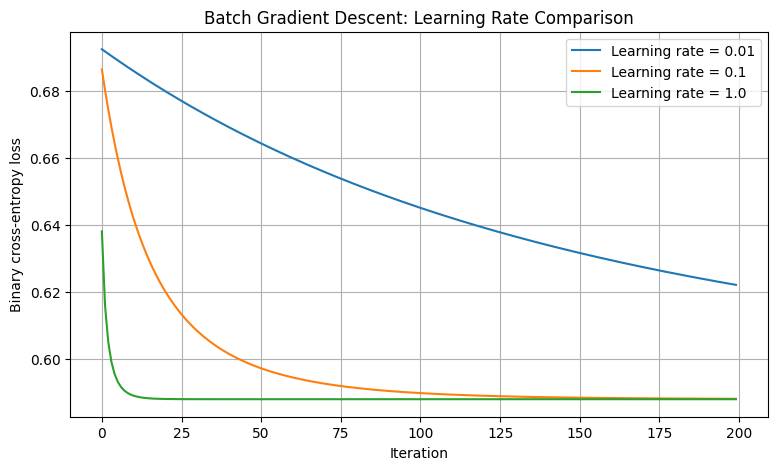

In [ ]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def logistic_loss(X, y, w):
    p = np.clip(sigmoid(X @ w), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1-y) * np.log(1-p))

def batch_gradient_descent(X, y, lr, iterations=200):
    w = np.zeros(X.shape[1])
    losses = []

    for _ in range(iterations):
        p = sigmoid(X @ w)
        gradient = X.T @ (p - y) / len(y)
        w -= lr * gradient
        losses.append(logistic_loss(X, y, w))

    return w, losses

batch_results = {}

for lr in [0.01, 0.1, 1.0]:
    w, losses = batch_gradient_descent(X_sample, y_sample, lr)
    batch_results[lr] = (w, losses)
    print(f"Learning rate {lr}: initial loss ~0.693, final loss {losses[-1]:.6f}")

plt.figure(figsize=(9, 5))
for lr, (_, losses) in batch_results.items():
    plt.plot(losses, label=f'Learning rate = {lr}')
plt.xlabel('Iteration')
plt.ylabel('Binary cross-entropy loss')
plt.title('Batch Gradient Descent: Learning Rate Comparison')
plt.legend()
plt.grid(True)
plt.show()

### Mini-batch SGD and Newton's method

Mini-batch SGD, lr=0.01: final loss=0.588253
Mini-batch SGD, lr=0.1: final loss=0.588334
Mini-batch SGD, lr=1.0: final loss=0.610142
Newton's method iterations: 20
Newton's method final loss: 0.588102


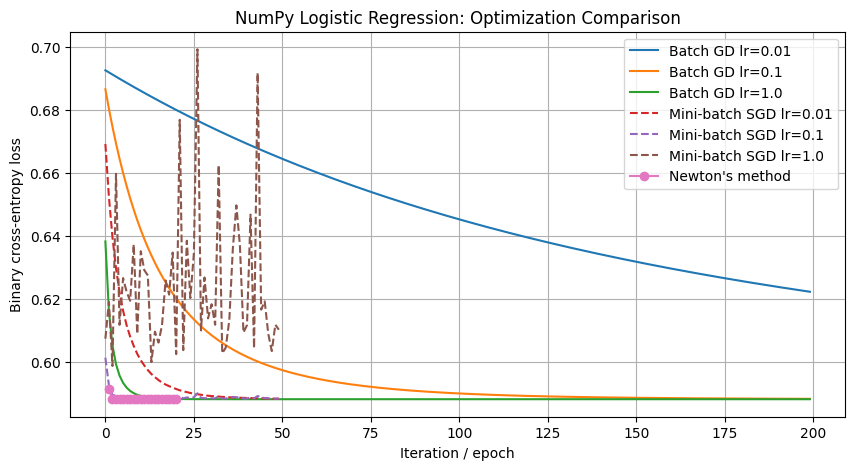

In [ ]:
# Mini-batch Stochastic Gradient Descent
def mini_batch_sgd(X, y, lr, epochs=50, batch_size=256):
    w = np.zeros(X.shape[1])
    losses = []
    rng = np.random.default_rng(42)

    for epoch in range(epochs):
        indices = rng.permutation(len(y))
        for start in range(0, len(y), batch_size):
            idx = indices[start:start + batch_size]
            p = sigmoid(X[idx] @ w)
            gradient = X[idx].T @ (p - y[idx]) / len(idx)
            w -= lr * gradient

        losses.append(logistic_loss(X, y, w))

    return w, losses

sgd_results = {}
for lr in [0.01, 0.1, 1.0]:
    w, losses = mini_batch_sgd(X_sample, y_sample, lr)
    sgd_results[lr] = (w, losses)
    print(f"Mini-batch SGD, lr={lr}: final loss={losses[-1]:.6f}")

# Newton's method
def newton_method(X, y, iterations=20, tolerance=1e-6):
    w = np.zeros(X.shape[1])
    losses = []

    for i in range(iterations):
        p = sigmoid(X @ w)
        gradient = X.T @ (p - y) / len(y)

        weights = p * (1 - p)
        hessian = (X.T * weights) @ X / len(y)
        hessian += 1e-6 * np.eye(X.shape[1])  # numerical stability

        step = np.linalg.solve(hessian, gradient)
        w -= step
        losses.append(logistic_loss(X, y, w))

        if np.linalg.norm(step) < tolerance:
            break

    return w, losses

newton_w, newton_losses = newton_method(X_sample, y_sample)
print("Newton's method iterations:", len(newton_losses))
print("Newton's method final loss:", round(newton_losses[-1], 6))

# Plot batch GD and mini-batch SGD for all required learning rates
plt.figure(figsize=(10, 5))
for lr, (_, losses) in batch_results.items():
    plt.plot(losses, label=f'Batch GD lr={lr}')
for lr, (_, losses) in sgd_results.items():
    plt.plot(losses, linestyle='--', label=f'Mini-batch SGD lr={lr}')
plt.plot(range(1, len(newton_losses) + 1), newton_losses,
         marker='o', label="Newton's method")
plt.xlabel('Iteration / epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title('NumPy Logistic Regression: Optimization Comparison')
plt.legend()
plt.grid(True)
plt.show()

### Final convergence comparison cell

In [ ]:
all_losses = {
    **{f"Batch GD (lr={lr})": losses
       for lr, (_, losses) in batch_results.items()},
    **{f"Mini-batch SGD (lr={lr})": losses
       for lr, (_, losses) in sgd_results.items()},
    "Newton's method": newton_losses
}

best_final_loss = min(losses[-1] for losses in all_losses.values())
target_loss = best_final_loss + 0.001

print("Best final loss:", round(best_final_loss, 6))
print("Convergence threshold:", round(target_loss, 6))
print("\nFirst iteration/epoch reaching threshold:")

for name, losses in all_losses.items():
    reached = next(
        (i + 1 for i, loss in enumerate(losses)
         if np.isfinite(loss) and loss <= target_loss),
        None
    )
    print(f"{name}: {reached if reached else 'Not reached'}")

Best final loss: 0.588102
Convergence threshold: 0.589102

First iteration/epoch reaching threshold:
Batch GD (lr=0.01): Not reached
Batch GD (lr=0.1): 122
Batch GD (lr=1.0): 12
Mini-batch SGD (lr=0.01): 32
Mini-batch SGD (lr=0.1): 5
Mini-batch SGD (lr=1.0): Not reached
Newton's method: 2


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, roc_auc_score
)

# Features only — exclude IDs, timestamps, and the true rating
feature_cols = [
    'user_avg_rating',
    'user_rating_count',
    'movie_avg_rating',
    'movie_rating_count'
] + genre_names

X_train = train_features[feature_cols].to_numpy(dtype=float)
y_train = train_features['liked'].to_numpy()

X_test = test_features[feature_cols].to_numpy(dtype=float)
y_test = test_features['liked'].to_numpy()

models = {
    'L1': make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty='l1', solver='liblinear',
            C=1.0, max_iter=1000, random_state=42
        )
    ),
    'L2': make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty='l2', solver='lbfgs',
            C=1.0, max_iter=1000, random_state=42
        )
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    lr_model = model.named_steps['logisticregression']
    nonzero = int(np.count_nonzero(np.abs(lr_model.coef_) > 1e-8))

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilities),
        'Non-zero coefficients': nonzero
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,ROC-AUC,Non-zero coefficients
0,L1,0.6571,0.6608,0.8149,0.6953,23
1,L2,0.6574,0.6611,0.8151,0.6953,23


In [ ]:
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import time

# Use at most 10,000 training rows for faster SVM training
svm_sample = train_features.sample(n=10000, random_state=42)

X_svm = svm_sample[feature_cols].to_numpy(dtype=float)
y_svm = svm_sample['liked'].to_numpy()

# Test set remains untouched
X_test_svm = test_features[feature_cols].to_numpy(dtype=float)

svm_models = {
    'Linear SVM': make_pipeline(
        StandardScaler(),
        LinearSVC(C=1.0, max_iter=5000, random_state=42)
    ),
    'RBF SVM': make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
    )
}

svm_results = []

for name, model in svm_models.items():
    start = time.time()
    model.fit(X_svm, y_svm)
    elapsed = time.time() - start

    predictions = model.predict(X_test_svm)

    if name == 'Linear SVM':
        scores = model.decision_function(X_test_svm)
    else:
        scores = model.predict_proba(X_test_svm)[:, 1]

    svm_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, scores),
        'Training time (seconds)': round(elapsed, 2)
    })

display(pd.DataFrame(svm_results).round(4))

In [ ]:
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import time

# Use at most 10,000 training rows for faster SVM training
svm_sample = train_features.sample(n=10000, random_state=42)

X_svm = svm_sample[feature_cols].to_numpy(dtype=float)
y_svm = svm_sample['liked'].to_numpy()

# Test set remains untouched
X_test_svm = test_features[feature_cols].to_numpy(dtype=float)

svm_models = {
    'Linear SVM': make_pipeline(
        StandardScaler(),
        LinearSVC(C=1.0, max_iter=5000, random_state=42)
    ),
    'RBF SVM': make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
    )
}

svm_results = []

for name, model in svm_models.items():
    start = time.time()
    model.fit(X_svm, y_svm)
    elapsed = time.time() - start

    predictions = model.predict(X_test_svm)

    if name == 'Linear SVM':
        scores = model.decision_function(X_test_svm)
    else:
        scores = model.predict_proba(X_test_svm)[:, 1]

    svm_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, scores),
        'Training time (seconds)': round(elapsed, 2)
    })

display(pd.DataFrame(svm_results).round(4))

,Model,Accuracy,Precision,Recall,ROC-AUC,Training time (seconds)
0,Linear SVM,0.6557,0.6575,0.8229,0.6949,0.04
1,RBF SVM,0.6438,0.6443,0.8332,0.6778,32.64


In [ ]:
from sklearn.mixture import GaussianMixture

# Compute user averages from training data only
user_avg = train.groupby('user_id')['rating'].mean().reset_index()
user_avg.columns = ['user_id', 'avg_rating']

# Fit a 2-component Gaussian mixture using EM
gmm = GaussianMixture(n_components=2, random_state=42, n_init=10)
user_avg['cluster'] = gmm.fit_predict(user_avg[['avg_rating']])

print("User counts by group:")
print(user_avg['cluster'].value_counts().sort_index())

print("\nGroup summary:")
display(
    user_avg.groupby('cluster')['avg_rating']
    .agg(['count', 'mean', 'std', 'min', 'max'])
    .round(4)
)

User counts by group:
cluster
0    659
1     64
Name: count, dtype: int64

Group summary:


,count,mean,std,min,max
cluster,,,,,
0,659,3.5991,0.4425,1.3404,4.8696
1,64,5.0000,0.0000,5.0000,5.0000


In [ ]:
# Movie statistics from training data only
movie_summary = train.groupby('movie_id')['rating'].agg(
    rating_count='count',
    raw_average='mean'
).reset_index()

global_mean = train['rating'].mean()
m = 20  # Prior strength: equivalent to 20 ratings at the global mean

movie_summary['bayesian_average'] = (
    (movie_summary['rating_count'] * movie_summary['raw_average']
     + m * global_mean)
    / (movie_summary['rating_count'] + m)
)

# Add movie titles
movie_summary = movie_summary.merge(
    movies[['movie_id', 'title']], on='movie_id', how='left'
)

raw_top10 = movie_summary.sort_values(
    ['raw_average', 'rating_count'], ascending=[False, False]
).head(10)

bayesian_top10 = movie_summary.sort_values(
    ['bayesian_average', 'rating_count'], ascending=[False, False]
).head(10)

print("Global training mean:", round(global_mean, 4))
print("\nTop 10 by raw average:")
display(raw_top10[['movie_id', 'title', 'rating_count',
                    'raw_average']].round(4))

print("\nTop 10 by Bayesian average (m=20):")
display(bayesian_top10[['movie_id', 'title', 'rating_count',
                        'raw_average', 'bayesian_average']].round(4))

raw_ids = set(raw_top10['movie_id'])
bayes_ids = set(bayesian_top10['movie_id'])
print("\nMovies appearing in both lists:", len(raw_ids & bayes_ids))

Global training mean: 3.5341

Top 10 by raw average:


,movie_id,title,rating_count,raw_average
118,119,Maya Lin: A Strong Clear Vision (1994),2,5.0
1447,1500,Santa with Muscles (1996),2,5.0
1459,1512,"World of Apu, The (Apur Sansar) (1959)",2,5.0
810,814,"Great Day in Harlem, A (1994)",1,5.0
1107,1122,They Made Me a Criminal (1939),1,5.0
1174,1189,Prefontaine (1997),1,5.0
1273,1293,Star Kid (1997),1,5.0
1274,1294,Ayn Rand: A Sense of Life (1997),1,5.0
1315,1347,"Ballad of Narayama, The (Narayama Bushiko) (1958)",1,5.0
1323,1358,The Deadly Cure (1996),1,5.0



Top 10 by Bayesian average (m=20):


,movie_id,title,rating_count,raw_average,bayesian_average
445,446,Burnt Offerings (1976),95,4.5684,4.3885
63,64,"Shawshank Redemption, The (1994)",207,4.4638,4.3819
317,318,Schindler's List (1993),204,4.4510,4.3691
407,408,"Close Shave, A (1995)",80,4.5625,4.3568
482,483,Casablanca (1942),161,4.4348,4.3353
168,169,"Wrong Trousers, The (1993)",81,4.4938,4.3038
49,50,Star Wars (1977),405,4.3358,4.2981
97,98,"Silence of the Lambs, The (1991)",269,4.3457,4.2896
600,603,Rear Window (1954),131,4.4046,4.2893
312,313,Titanic (1997),170,4.3706,4.2825



Movies appearing in both lists: 0


In [ ]:
from sklearn.ensemble import IsolationForest

# Use training ratings only
global_mean = train['rating'].mean()

# Part A: User rating bias
user_outliers = train.groupby('user_id')['rating'].agg(
    rating_count='count',
    avg_rating='mean'
).reset_index()

user_outliers['rating_bias'] = user_outliers['avg_rating'] - global_mean
user_outliers['abs_bias'] = user_outliers['rating_bias'].abs()

bias_std = user_outliers['rating_bias'].std(ddof=0)
user_outliers['bias_zscore'] = (
    (user_outliers['rating_bias'] - user_outliers['rating_bias'].mean())
    / (bias_std if bias_std > 0 else 1)
)

user_iso = IsolationForest(contamination=0.05, random_state=42)
user_outliers['isolation_flag'] = user_iso.fit_predict(
    user_outliers[['rating_bias', 'rating_count']]
)

print("Top 5 users by absolute rating bias:")
display(
    user_outliers.sort_values('abs_bias', ascending=False)
    [['user_id', 'rating_count', 'avg_rating',
      'rating_bias', 'bias_zscore', 'isolation_flag']]
    .head(5).round(4)
)

# Part B: Movie rating variance
movie_outliers = train.groupby('movie_id')['rating'].agg(
    rating_count='count',
    avg_rating='mean',
    rating_variance='var'
).reset_index()

movie_outliers['rating_variance'] = movie_outliers['rating_variance'].fillna(0)

var_std = movie_outliers['rating_variance'].std(ddof=0)
movie_outliers['variance_zscore'] = (
    (movie_outliers['rating_variance'] - movie_outliers['rating_variance'].mean())
    / (var_std if var_std > 0 else 1)
)

movie_iso = IsolationForest(contamination=0.05, random_state=42)
movie_outliers['isolation_flag'] = movie_iso.fit_predict(
    movie_outliers[['rating_variance', 'rating_count']]
)

movie_outliers = movie_outliers.merge(
    movies[['movie_id', 'title']], on='movie_id', how='left'
)

print("\nTop 5 movies by rating variance:")
display(
    movie_outliers.sort_values('rating_variance', ascending=False)
    [['movie_id', 'title', 'rating_count', 'avg_rating',
      'rating_variance', 'variance_zscore', 'isolation_flag']]
    .head(5).round(4)
)

Top 5 users by absolute rating bias:


,user_id,rating_count,avg_rating,rating_bias,bias_zscore,isolation_flag
120,158,47,1.3404,-2.1937,-4.1071,-1
199,264,737,1.8345,-1.6997,-3.2555,-1
448,574,224,2.0580,-1.4761,-2.8701,-1
625,794,1,5.0000,1.4659,2.2011,1
43,59,1,5.0000,1.4659,2.2011,1



Top 5 movies by rating variance:


,movie_id,title,rating_count,avg_rating,rating_variance,variance_zscore,isolation_flag
1552,1612,"Leading Man, The (1996)",2,3.0,8.0,9.2615,-1
1541,1598,City of Industry (1997),2,3.0,8.0,9.2615,-1
1535,1591,Duoluo tianshi (1995),2,3.0,8.0,9.2615,-1
1160,1175,Hugo Pool (1997),5,3.4,4.8,4.9994,-1
1478,1534,Twin Town (1997),2,2.5,4.5,4.5998,-1
